# Ab initio dynamics with PySCF CASSCF

Run **mean-field (Ehrenfest)** and **fewest-switches surface hopping (FSSH)** dynamics for LiH using two singlet, equally weighted SA-CASSCF(2,2) states in the STO-3G basis.

We calculate normal modes once, sample the ground-state harmonic Wigner distribution, add an outward stretch impulse, start the electrons on S1, and run both algorithms with matching nuclear seeds. The saved plots show ensemble populations and an individual **accepted S1 → S0 surface hop**. All electronic structure calculations use PySCF; Q-Chem and ASE are not required.

This is an energetic, reproducible hopping demonstration. Seed 13 is deliberately included because it hops with these settings. The small, selected ensemble is not an unbiased estimate of a hopping yield or rate.

## 1. Prepare the notebook environment

From the **repository root**, install QC Lab and the plotting/kernel dependencies into the Python environment you will select as this notebook's kernel:

```bash
python -m pip install -e '.[pyscf]' matplotlib ipykernel
```

Open this notebook in a Jupyter-capable editor, select that environment, and run the cells in order. The calculator targets PySCF 2.14.x. Installation is a separate step; Run All does not install packages.

In [ ]:
import os
import copy
import warnings
from time import perf_counter

# Keep this small example to one thread per electronic structure calculation.
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "1")

import numpy as np
import matplotlib.pyplot as plt
import pyscf

from qclab import Simulation
from qclab.algorithms import MeanFieldAbInitio, FewestSwitchesSurfaceHoppingAbInitio
from qclab.dynamics import serial_driver
from qclab.functions import z_to_q, z_to_p, qp_to_z
from qclab.interfaces import QCLabPySCFInterface
from qclab.models import AbInitio
from qclab.numerical_constants import (
    AMU_TO_EMASS,
    ANGSTROM_TO_BOHR,
    AU_TIME_TO_FS,
    INVCM_TO_HA,
    HA_TO_EV,
    K_B_HA_PER_K,
)

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Some macOS wheels run serially and warn whenever a thread limit is requested.
warnings.filterwarnings(
    "ignore",
    message="OpenMP is not available.*",
    category=UserWarning,
    module=r"pyscf\.lib\.misc",
)
print("PySCF version:", pyscf.__version__)

## 2. Specify the molecule and electronic structure method

QC Lab uses **Bohr** for Cartesian positions, **electron masses** for atomic masses, **Hartree** for energy, and **atomic units** for propagation time. The reference Li–H bond is 3.0 Bohr (about 1.59 Å), with lithium-7/hydrogen-1 isotopic masses converted explicitly.

`num_quantum_states=2` includes S0 and S1. The interface optimizes one common orbital set with equal state weights. `ncas=2` selects two active orbitals and `nelecas=2` two active electrons; LiH also has one doubly occupied inactive orbital. All retained states are singlets.

In [29]:
atom_names = ["Li", "H"]
atom_positions = np.array([[0.0, 0.0, 0.0], [0.0, 0.0, 3.0]])  # Bohr.
atom_masses = np.array([7.0160034366, 1.00782503223]) * AMU_TO_EMASS
num_quantum_states = 2

calculator_args = {
    "method_es": "casscf",
    "basis": "sto-3g",
    "charge": 0,
    "multiplicity": 1,
    "ncas": 2,
    "nelecas": 2,
    "num_threads": 1,
    "max_memory": 1000,  # MB per PySCF calculation.
    "scf_options": {"conv_tol": 1e-10},
    "casscf_options": {
        "conv_tol": 1e-9,
        "conv_tol_grad": 1e-6,
        "ah_conv_tol": 1e-14,
    },
}

## 3. Calculate the vibrational modes once

`normal_modes(state_ind=0)` forms a central-difference Hessian of the S0 energy using analytic gradients **within the same SA-CASSCF model**. It removes translations and rotations, returning model-ready constants. A diatomic has one internal stretch.

The columns of `normal_mode` are orthonormal **mass-weighted** eigenvectors. `harmonic_frequency` contains angular frequencies in atomic units. The reference geometry is supplied as-is; this routine does not optimize it. For an application, use a suitable equilibrium geometry and check the Hessian displacement and electronic convergence.

We choose the stretch eigenvector sign so its H-z component is positive. This leaves the Wigner distribution unchanged and makes the selected seed reproducible across eigensolver sign conventions.

In [30]:
reference_calculator = QCLabPySCFInterface(
    atom_positions=atom_positions,
    atom_masses=atom_masses,
    atom_names=atom_names,
    num_quantum_states=num_quantum_states,
    **calculator_args,
)
start = perf_counter()
vibrations = reference_calculator.normal_modes(state_ind=0, delta=1e-3)
frequencies = vibrations["harmonic_frequency"]
modes = vibrations["normal_mode"]
# Fix the arbitrary eigenvector sign so each seed maps to the same stretch sample.
if modes[5, 0] < 0:
    modes *= -1

assert vibrations["normal_mode_convention"] == "mass_weighted"
assert frequencies.shape == (1,)
assert np.isrealobj(frequencies) and np.all(np.isfinite(frequencies)) and np.all(frequencies > 0)
np.testing.assert_allclose(modes.T @ modes, np.eye(len(frequencies)), atol=1e-8)
print("Vibrational frequencies (cm^-1):", frequencies / INVCM_TO_HA)
print("Normal-mode shape:", modes.shape)
print("Mode calculation: %.2f s" % (perf_counter() - start))

Vibrational frequencies (cm^-1): [1669.70061343]
Normal-mode shape: (6, 1)
Mode calculation: 0.64 s


## 4. Sample Wigner initial conditions and add a stretch impulse

At `temperature_K=0`, the harmonic Wigner distribution retains the quantum zero-point widths in **both positions and momenta**. QC Lab applies the canonical transformations

\[
q=q_0+M^{-1/2}UQ,\qquad p=M^{1/2}UP,
\]

where $U$ contains the mass-weighted normal modes. Passing all three returned mode constants selects this convention automatically.

To make a hop visible within a short propagation, we add an **energetic outward stretch impulse** after sampling. With reduced nuclear mass $\mu$, the increments are $\Delta p_{\mathrm{Li}}=-\mu\,\Delta v\,\hat r$ and $\Delta p_{\mathrm{H}}=+\mu\,\Delta v\,\hat r$. The impulse preserves the initial center-of-mass momentum and increases the relative stretch velocity by **0.03 Bohr/a.u.** Its nominal energy is about **19.7 eV**; the actual sampled kinetic-energy change also includes a cross term with the Wigner momentum.

Both algorithms receive the same impulse and the same explicit seeds, `np.arange(100)`. Seed 13 was selected for a reproducible stochastic hop. We leave the FSSH random-number generator, hopping probabilities, and energy-conserving momentum rescaling unchanged. Electrons initially occupy S1. We propagate 100 trajectories for 100 a.u. (about 2.42 fs).

Set **`temperature_K`** in the next cell; it is converted to the model's `kBT` in Hartree. For example, 10 K corresponds to `kBT=3.1668e-5`, and 300 K to approximately `0.000950`. Setting `kBT=10` directly would mean about **3.16 million kelvin**, which produces extreme geometries outside this harmonic sampling model.

The stretch impulse is additional energy, independent of temperature. For a thermal initial ensemble without this excitation, set `stretch_velocity_kick=0.0` in both notebooks.

Stretched LiH remains electronically solvable, but ordinary Hartree–Fock SCF iterations can stall before CASSCF or CMS-PDFT starts. The calculator now makes one Newton SCF retry with the same reference and convergence tolerances. Successful recovery is logged; unresolved failures identify the trajectory seed and geometry. This numerical recovery is separate from checking the harmonic sampling approximation and the time step at extreme nuclear configurations.


In [ ]:
settings = {
    "num_trajs": 100,
    "batch_size": 100,
    "tmax": 100.0,
    "dt_update": 1.0,
    "dt_collect": 1.0,
    "progress_bar": True,
}
seeds = np.arange(settings["num_trajs"], dtype=int)  # np.array([13, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 14, 15, 16, 17, 18, 19,
#                  20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39], dtype=int)
initial_electronic_state = 1  # Zero-based: 0 = S0, 1 = S1.
stretch_velocity_kick = 0.03  # Added relative nuclear velocity, Bohr / a.u. of time.
reduced_mass = np.prod(atom_masses) / np.sum(atom_masses)

temperature_K = 0.0  # Kelvin. Set to 10.0 for 10 K or 300.0 for 300 K.
if not np.isfinite(temperature_K) or temperature_K < 0:
    raise ValueError("temperature_K must be finite and nonnegative.")

model_constants = {
    "calculator": "pyscf",
    "calculator_args": calculator_args,
    "atom_names": atom_names,
    "atom_positions": atom_positions,
    "atom_masses": atom_masses,
    "num_quantum_states": num_quantum_states,
    "kBT": temperature_K * K_B_HA_PER_K,  # Internal thermal energy in Hartree.
    **vibrations,
}
if seeds is not None:
    assert len(seeds) == settings["num_trajs"]
    print("Trajectory seeds:", seeds)
print("Propagation time: %.3f fs" % (settings["tmax"] * AU_TIME_TO_FS))
print("Nominal stretch-impulse energy: %.2f eV" % (
    0.5 * reduced_mass * stretch_velocity_kick**2 * HA_TO_EV
))
print("Sampling temperature: %.1f K; kBT = %.8g Hartree" % (
    temperature_K, model_constants["kBT"]
))


In [32]:
def init_kicked_wigner(model, parameters, **kwargs):
    """Sample full-width Wigner coordinates, then add a COM-preserving impulse."""
    z = AbInitio.init_classical(model, parameters, **kwargs)
    mass = model.constants.classical_coordinate_mass
    weight = model.constants.classical_coordinate_weight
    q = z_to_q(z, mass, weight).reshape((-1, 2, 3))
    p = z_to_p(z, mass, weight).reshape((-1, 2, 3))
    bond = q[:, 1] - q[:, 0]
    direction = bond / np.linalg.norm(bond, axis=1)[:, None]
    impulse = reduced_mass * stretch_velocity_kick * direction
    p[:, 0] -= impulse
    p[:, 1] += impulse
    return qp_to_z(q.reshape((-1, 6)), p.reshape((-1, 6)), mass, weight)


# Preview the same kicked Wigner samples that initialize each dynamics run.
preview_model = AbInitio(copy.deepcopy(model_constants))
z_initial = init_kicked_wigner(preview_model, {}, seed=seeds)
masses = preview_model.constants.classical_coordinate_mass[np.newaxis, :]
weights = preview_model.constants.classical_coordinate_weight[np.newaxis, :]
q_initial = z_to_q(z_initial, masses, weights).reshape(len(seeds), len(atom_names), 3)
p_initial = z_to_p(z_initial, masses, weights).reshape(len(seeds), len(atom_names), 3)
bond_lengths = np.linalg.norm(q_initial[:, 1] - q_initial[:, 0], axis=1) / ANGSTROM_TO_BOHR

assert np.all(np.isfinite(z_initial))
np.testing.assert_allclose(p_initial.sum(axis=1), 0.0, atol=1e-10)
print("Seed   Li-H distance (Angstrom)   H momentum along z (a.u.)")
for seed, distance, momentum in zip(seeds, bond_lengths, p_initial[:, 1, 2]):
    print("%4d   %22.6f   %27.6f" % (seed, distance, momentum))

Seed   Li-H distance (Angstrom)   H momentum along z (a.u.)
   0                 1.776351                     49.181170
   1                 1.761397                     46.679785
   2                 1.542923                     48.052919
   3                 1.778981                     49.271032
   4                 1.592944                     49.427855
   5                 1.634759                     47.374117
   6                 1.554159                     49.994058
   7                 1.768481                     47.040240
   8                 1.597294                     50.889588
   9                 1.587650                     47.476273
  10                 1.730061                     49.960131
  11                 1.774788                     47.484853
  12                 1.638159                     46.507566
  13                 1.511280                     50.055270
  14                 1.753582                     48.387750
  15                 1.554101           

## 5. Build a fresh simulation for each algorithm

Each model uses the same `init_kicked_wigner` ingredient, which calls the standard Wigner sampler before adding the specified impulse. Each run gets its own model and algorithm so its calculator cache and trajectory state are independent. The normal modes are reused; neither run repeats the Hessian calculation.

For these adiabatic algorithms, set **`initial_state["wf_adb"]`** to a complex NumPy array.

In [33]:
def make_simulation(algorithm_class):
    sim = Simulation(copy.deepcopy(settings))
    sim.model = AbInitio(copy.deepcopy(model_constants))
    sim.model.ingredients = sim.model.ingredients + [("init_classical", init_kicked_wigner)]
    sim.algorithm = algorithm_class()
    wf_initial = np.zeros(num_quantum_states, dtype=complex)
    wf_initial[initial_electronic_state] = 1.0
    sim.initial_state["wf_adb"] = wf_initial
    return sim

## 6. Run mean-field (Ehrenfest) dynamics

`MeanFieldAbInitio` evolves the electronic amplitudes and moves the nuclei under the electronic mean force. It uses the CASSCF state gradients and derivative couplings. The driver returns trajectory-averaged results.

In [34]:
mean_field_sim = make_simulation(MeanFieldAbInitio)
start = perf_counter()
mean_field_data = serial_driver(mean_field_sim, seeds=seeds.copy())
print("Mean-field calculation: %.2f s" % (perf_counter() - start))

100%|██████████| 101/101 [17:36<00:00, 10.46s/it]

Mean-field calculation: 1056.60 s


## 7. Run fewest-switches surface hopping and retain individual surfaces

`FewestSwitchesSurfaceHoppingAbInitio` moves the nuclei on an active adiabatic surface, with stochastic hops between surfaces. Its default electronic propagation uses wavefunction overlaps; derivative couplings are needed for momentum rescaling on attempted hops. `fssh_deterministic=False` gives stochastic FSSH.

The small collect task below **only copies** each trajectory's seed, time, active surface, and nuclear coordinates. This retains individual histories alongside the driver's ensemble average. A change in an active-surface index records an accepted hop, rather than a frustrated attempt.

In [35]:
fssh_history = []


def collect_surface_history(
    sim, state, parameters, *, seed_name="seed", time_name="t",
    surface_name="act_surf_ind", z_name="z",
):
    """Retain per-trajectory copies for plotting; do not change the dynamics."""
    fssh_history.append({
        "seed": state[seed_name].copy(),
        "time": state[time_name].copy(),
        "surface": state[surface_name].copy(),
        "z": state[z_name].copy(),
    })
    return state, parameters


fssh_sim = make_simulation(FewestSwitchesSurfaceHoppingAbInitio)
fssh_sim.algorithm.collect_recipe = fssh_sim.algorithm.collect_recipe + [collect_surface_history]
start = perf_counter()
fssh_data = serial_driver(fssh_sim, seeds=seeds.copy())
print("FSSH calculation: %.2f s" % (perf_counter() - start))

100%|██████████| 101/101 [11:44<00:00,  6.97s/it]

FSSH calculation: 704.22 s


## 8. Extract the populations and identify accepted hops

Both results use `data_dict["dm_adb"]`, but their **diagonal estimators differ**:

- **Mean field:** the ensemble average of electronic populations $|c_i|^2$.
- **Stochastic FSSH:** the fraction of trajectories on each active surface. QC Lab replaces this density-matrix diagonal with active-surface occupations when collecting the observable.

With 100 trajectories, one hop changes a surface fraction by 0.01. Results are already averaged over trajectories; no extra averaging axis is needed. The individual histories below identify which trajectory hopped and when. The selected seed makes the event reproducible; the fraction from this selected ensemble is not a yield estimate.

In [36]:
def population_series(data):
    time_fs = np.asarray(data.data_dict["t"]) * AU_TIME_TO_FS
    density = np.asarray(data.data_dict["dm_adb"])
    populations = np.diagonal(density, axis1=-2, axis2=-1).real.copy()
    assert populations.shape == (len(time_fs), num_quantum_states)
    assert np.all(np.isfinite(populations))
    np.testing.assert_allclose(populations.sum(axis=1), 1.0, atol=1e-7)
    assert np.all(populations >= -1e-7) and np.all(populations <= 1.0 + 1e-7)
    return time_fs, populations

mean_field_time, mean_field_populations = population_series(mean_field_data)
fssh_time, fssh_populations = population_series(fssh_data)
np.testing.assert_allclose(mean_field_time, fssh_time)
np.testing.assert_array_equal(mean_field_data.data_dict["seed"], fssh_data.data_dict["seed"])

In [37]:
# Reconstruct each trajectory's collected active-surface history.
surface_histories = {}
for frame in fssh_history:
    for seed, time, surface, z in zip(frame["seed"], frame["time"], frame["surface"], frame["z"]):
        surface_histories.setdefault(int(seed), []).append((float(time), int(surface), z.copy()))

hop_events = []
for seed, rows in surface_histories.items():
    rows.sort(key=lambda row: row[0])
    times = np.array([row[0] for row in rows])
    surfaces = np.array([row[1] for row in rows])
    for index in np.flatnonzero(np.diff(surfaces) != 0) + 1:
        q = z_to_q(rows[index][2], fssh_sim.model.constants.classical_coordinate_mass,
                   fssh_sim.model.constants.classical_coordinate_weight).reshape((2, 3))
        hop_events.append({
            "seed": seed,
            "time_fs": times[index] * AU_TIME_TO_FS,
            "source": surfaces[index - 1],
            "destination": surfaces[index],
            "bond_angstrom": np.linalg.norm(q[1] - q[0]) / ANGSTROM_TO_BOHR,
        })

assert any(event["seed"] == 13 and event["source"] == 1 and event["destination"] == 0
           for event in hop_events), "Expected the demonstration's accepted S1-to-S0 hop."
print("Accepted hops (surface-index changes):")
for event in sorted(hop_events, key=lambda event: event["time_fs"]):
    print("  Seed %d: S%d -> S%d at %.3f fs; Li-H distance %.3f Angstrom" % (
        event["seed"], event["source"], event["destination"], event["time_fs"], event["bond_angstrom"]
    ))

Accepted hops (surface-index changes):
  Seed 29: S1 -> S0 at 0.508 fs; Li-H distance 1.889 Angstrom
  Seed 13: S1 -> S0 at 0.895 fs; Li-H distance 2.123 Angstrom
  Seed 48: S1 -> S0 at 1.645 fs; Li-H distance 2.501 Angstrom


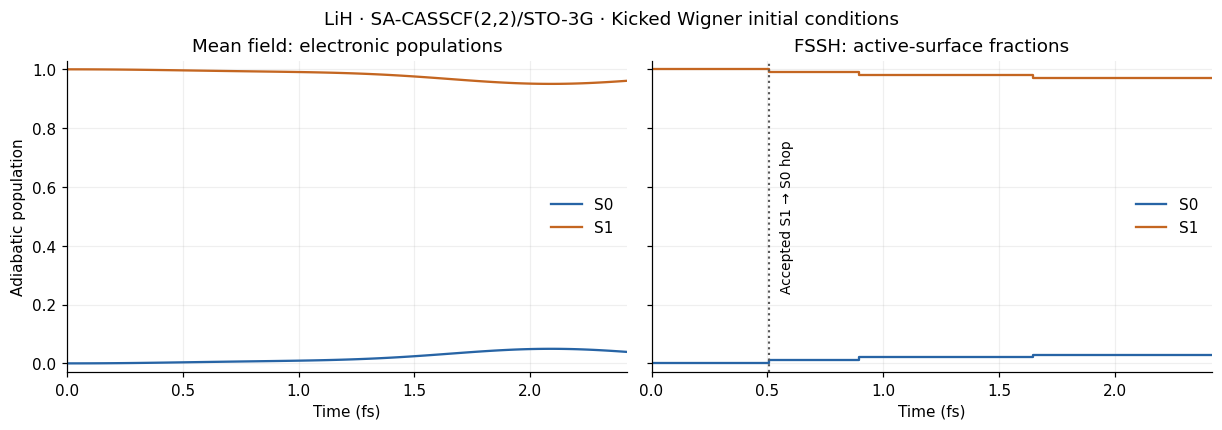

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True, constrained_layout=True)
colors = ["#2764a5", "#c46621"]
for state in range(num_quantum_states):
    axes[0].plot(mean_field_time, mean_field_populations[:, state], color=colors[state], label="S%d" % state)
    axes[1].step(fssh_time, fssh_populations[:, state], where="post", color=colors[state], label="S%d" % state)
axes[0].set_title("Mean field: electronic populations")
axes[1].set_title("FSSH: active-surface fractions")
first_hop = min(hop_events, key=lambda event: event["time_fs"])
axes[1].axvline(first_hop["time_fs"], color="0.35", linestyle=":", linewidth=1.4)
axes[1].annotate("Accepted S%d → S%d hop" % (first_hop["source"], first_hop["destination"]),
                 xy=(first_hop["time_fs"], 0.5), xytext=(7, 0), textcoords="offset points",
                 fontsize=9, rotation=90, va="center")
axes[0].set_ylabel("Adiabatic population")
for ax in axes:
    ax.set_xlabel("Time (fs)")
    ax.set_ylim(-0.03, 1.03)
    ax.set_xlim(mean_field_time[0], mean_field_time[-1])
    ax.grid(alpha=0.2)
    ax.legend(frameon=False)
fig.suptitle("LiH · SA-CASSCF(2,2)/STO-3G · Kicked Wigner initial conditions")
plt.show()

The next plot compares population in the initially unoccupied state. The FSSH step is an accepted surface hop; the smooth mean-field curve is an electronic population. The last plot then shows the hopping trajectory's discrete active-surface index directly.

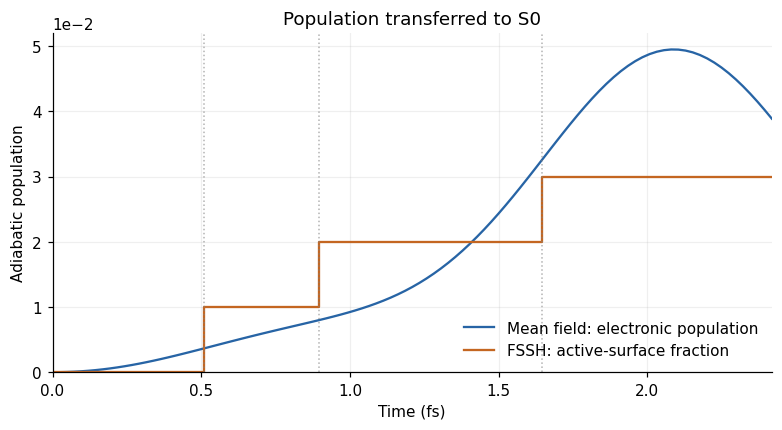

In [39]:
other_state = 1 - initial_electronic_state
fig, ax = plt.subplots(figsize=(7.0, 3.8), constrained_layout=True)
ax.plot(mean_field_time, mean_field_populations[:, other_state], label="Mean field: electronic population", color=colors[0])
ax.step(fssh_time, fssh_populations[:, other_state], where="post", label="FSSH: active-surface fraction", color=colors[1])
ax.set(title="Population transferred to S%d" % other_state, xlabel="Time (fs)", ylabel="Adiabatic population")
ax.set_xlim(mean_field_time[0], mean_field_time[-1])
for event in hop_events:
    ax.axvline(event["time_fs"], color="0.5", linestyle=":", linewidth=1, alpha=0.6)
ax.set_ylim(bottom=0)
ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0))
ax.grid(alpha=0.2)
ax.legend(frameon=False)
plt.show()

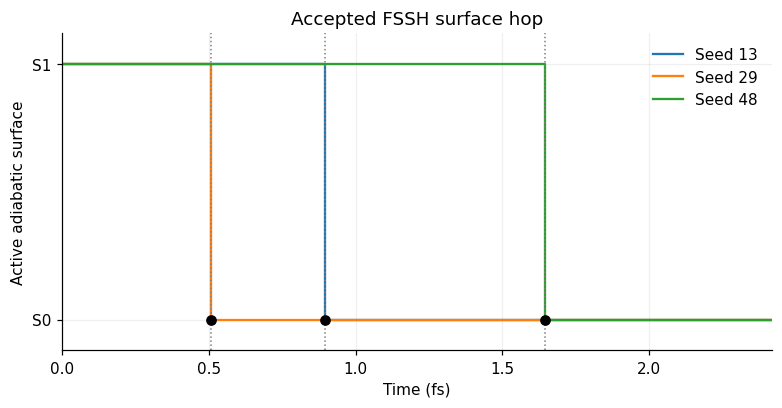

In [40]:
hopping_seeds = sorted({event["seed"] for event in hop_events})
fig, ax = plt.subplots(figsize=(7.0, 3.6), constrained_layout=True)
for seed in hopping_seeds:
    rows = surface_histories[seed]
    time_fs = np.array([row[0] for row in rows]) * AU_TIME_TO_FS
    active_surface = np.array([row[1] for row in rows])
    ax.step(time_fs, active_surface, where="post", label="Seed %d" % seed)
for event in hop_events:
    ax.scatter(event["time_fs"], event["destination"], color="black", zorder=3)
    ax.axvline(event["time_fs"], color="0.5", linestyle=":", linewidth=1)
ax.set(title="Accepted FSSH surface hop", xlabel="Time (fs)", ylabel="Active adiabatic surface")
ax.set_yticks([0, 1], ["S0", "S1"])
ax.set_ylim(-0.12, 1.12)
ax.set_xlim(fssh_time[0], fssh_time[-1])
ax.legend(frameon=False)
ax.grid(alpha=0.2)
plt.show()

## 9. Check the output and adapt the example

The checks above verify finite populations and population conservation. Inspect total-energy drift as another numerical diagnostic; reduce the time step and tighten electronic convergence when checking your application. Matching seeds make the nuclear sampling comparable, while finite-ensemble FSSH remains stochastic.

In [41]:
for label, data, populations in (
    ("Mean field", mean_field_data, mean_field_populations),
    ("FSSH", fssh_data, fssh_populations),
):
    energy = np.real(data.data_dict["quantum_energy"] + data.data_dict["classical_energy"])
    assert np.all(np.isfinite(energy))
    print(label)
    print("  Final adiabatic populations:", populations[-1])
    print("  Maximum population-sum error: %.3e" % np.max(np.abs(populations.sum(axis=1) - 1.0)))
    print("  Maximum total-energy change: %.3e Hartree" % np.max(np.abs(energy - energy[0])))

Mean field
  Final adiabatic populations: [0.03888636 0.96111364]
  Maximum population-sum error: 6.439e-15
  Maximum total-energy change: 1.988e-04 Hartree
FSSH
  Final adiabatic populations: [0.03 0.97]
  Maximum population-sum error: 0.000e+00
  Maximum total-energy change: 1.246e-05 Hartree


To explore further:

- Set `temperature_K` to the desired nuclear sampling temperature in kelvin, using the same value in both notebooks for matching samples. The electronic calculation itself remains a zero-electronic-temperature calculation. Check the sampled bond range and time-step convergence when raising temperature.
- Set `stretch_velocity_kick=0.0` to recover un-kicked Wigner sampling. A short LiH trajectory may then show no hops: the S0/S1 coupling region is reached less readily.
- For sampling studies, replace the selected seeds with a larger unbiased seed set and update `settings["num_trajs"]`. Do not infer a hopping rate from this demonstration ensemble.
- Increase `settings["tmax"]` to follow later dynamics. `batch_size` controls how many trajectory calculators are retained together.
- Vary `dt_update` to check time-step convergence; keep `dt_collect` at least as large as `dt_update`. Stochastic decisions on a different time grid need not reproduce the same hop times.
- Change `initial_electronic_state` to 0 to start on S0, or set a normalized complex superposition in `make_simulation`. If you change the initial conditions, remove or adapt the seed-13 demonstration assertion.
- Change the molecule, basis, and active space for your problem, and recalculate its normal modes. The impulse helper here is specific to a diatomic. Wigner sampling requires real, positive internal frequencies.
- To save averaged results, call `mean_field_data.save("lih_mean_field.h5")` and `fssh_data.save("lih_fssh.h5")` after the runs. The individual surface histories are retained separately in `surface_histories`.

This backend supports real, equal-weight SA-CASSCF states of one spin multiplicity. Larger ensembles, longer trajectories, and larger active spaces increase the computational cost.